# SQL Analytics Notebook — Palmer Penguins

Exploratory analysis of the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) dataset (344 penguins, 3 species, 3 islands, 2007–2009; CC0) using **SQL in SQLite**.

Every query lives in `sql/queries/` — this notebook is generated from them by `build_notebook.py`. Each section names the SQL technique it shows.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams.update({"figure.figsize": (6, 3.5), "figure.dpi": 72})
from analytics import build_database, load_query, run_query

conn = build_database()  # in-memory SQLite, loaded from data/*.csv
pd.read_sql_query("SELECT * FROM penguins LIMIT 5", conn)

,id,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,4,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,5,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## Schema

```sql
-- Schema for the Palmer Penguins analytics database.
-- A small star-ish layout: one fact table of measurements and one
-- dimension table describing each species.

DROP TABLE IF EXISTS penguins;
DROP TABLE IF EXISTS species;

CREATE TABLE species (
    species         TEXT PRIMARY KEY,
    scientific_name TEXT NOT NULL,
    genus           TEXT NOT NULL
);

CREATE TABLE penguins (
    id                INTEGER PRIMARY KEY,           -- surrogate key (row order in CSV)
    species           TEXT NOT NULL REFERENCES species(species),
    island            TEXT NOT NULL,
    bill_length_mm    REAL,                          -- NULL when not measured
    bill_depth_mm     REAL,
    flipper_length_mm INTEGER,
    body_mass_g       INTEGER,
    sex               TEXT CHECK (sex IN ('male', 'female') OR sex IS NULL),
    year              INTEGER NOT NULL CHECK (year BETWEEN 2007 AND 2009)
);

-- Most analyses group by species/island, so index them.
CREATE INDEX idx_penguins_species_island ON penguins(species, island);
```

## 01 · Data quality: how many rows, and how many NULLs per column?

```sql
-- 01 · Data quality: how many rows, and how many NULLs per column?
-- Technique: conditional aggregation (SUM over a boolean expression).
SELECT
    COUNT(*)                                   AS total_rows,
    SUM(bill_length_mm    IS NULL)             AS missing_bill_length,
    SUM(bill_depth_mm     IS NULL)             AS missing_bill_depth,
    SUM(flipper_length_mm IS NULL)             AS missing_flipper_length,
    SUM(body_mass_g       IS NULL)             AS missing_body_mass,
    SUM(sex               IS NULL)             AS missing_sex
FROM penguins;
```

In [2]:
df = run_query(conn, "01_data_quality", as_frame=True)
df

,total_rows,missing_bill_length,missing_bill_depth,missing_flipper_length,missing_body_mass,missing_sex
0,344,2,2,2,2,11


## 02 · Where does each species live?

```sql
-- 02 · Where does each species live?
-- Technique: GROUP BY two columns + share-of-total via a window over the aggregate.
SELECT
    species,
    island,
    COUNT(*)                                                     AS n,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY species), 1)
                                                                 AS pct_of_species
FROM penguins
GROUP BY species, island
ORDER BY species, n DESC;
```

In [3]:
df = run_query(conn, "02_species_by_island", as_frame=True)
df

,species,island,n,pct_of_species
0,Adelie,Dream,56,36.8
1,Adelie,Torgersen,52,34.2
2,Adelie,Biscoe,44,28.9
3,Chinstrap,Dream,68,100.0
4,Gentoo,Biscoe,124,100.0


## 03 · Average body measurements per species and sex.

```sql
-- 03 · Average body measurements per species and sex.
-- Technique: aggregates ignore NULLs automatically; rows with unknown sex are excluded.
SELECT
    species,
    sex,
    COUNT(*)                          AS n,
    ROUND(AVG(bill_length_mm), 1)     AS avg_bill_length_mm,
    ROUND(AVG(bill_depth_mm), 1)      AS avg_bill_depth_mm,
    ROUND(AVG(flipper_length_mm), 1)  AS avg_flipper_length_mm,
    ROUND(AVG(body_mass_g), 0)        AS avg_body_mass_g,
    MIN(body_mass_g)                  AS min_body_mass_g,
    MAX(body_mass_g)                  AS max_body_mass_g
FROM penguins
WHERE sex IS NOT NULL
GROUP BY species, sex
ORDER BY species, sex;
```

In [4]:
df = run_query(conn, "03_summary_by_species_sex", as_frame=True)
df

,species,sex,n,avg_bill_length_mm,avg_bill_depth_mm,avg_flipper_length_mm,avg_body_mass_g,min_body_mass_g,max_body_mass_g
0,Adelie,female,73,37.3,17.6,187.8,3369.0,2850,3900
1,Adelie,male,73,40.4,19.1,192.4,4043.0,3325,4775
2,Chinstrap,female,34,46.6,17.6,191.7,3527.0,2700,4150
3,Chinstrap,male,34,51.1,19.3,199.9,3939.0,3250,4800
4,Gentoo,female,58,45.6,14.2,212.7,4680.0,3950,5200
5,Gentoo,male,61,49.5,15.7,221.5,5485.0,4750,6300


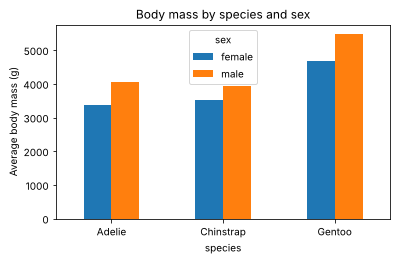

In [5]:
ax = df.pivot(index="species", columns="sex", values="avg_body_mass_g").plot.bar(rot=0)
ax.set_ylabel("Average body mass (g)")
ax.set_title("Body mass by species and sex")
plt.show()

## 04 · Top 3 heaviest penguins in each species.

```sql
-- 04 · Top 3 heaviest penguins in each species.
-- Technique: ROW_NUMBER() window function inside a CTE, then filter on the rank.
WITH ranked AS (
    SELECT
        id, species, island, sex, body_mass_g,
        ROW_NUMBER() OVER (
            PARTITION BY species
            ORDER BY body_mass_g DESC, id
        ) AS rank_in_species
    FROM penguins
    WHERE body_mass_g IS NOT NULL
)
SELECT species, rank_in_species, id, island, sex, body_mass_g
FROM ranked
WHERE rank_in_species <= 3
ORDER BY species, rank_in_species;
```

In [6]:
df = run_query(conn, "04_heaviest_per_species", as_frame=True)
df

,species,rank_in_species,id,island,sex,body_mass_g
0,Adelie,1,110,Biscoe,male,4775
1,Adelie,2,102,Biscoe,male,4725
2,Adelie,3,82,Torgersen,male,4700
3,Chinstrap,1,314,Dream,male,4800
4,Chinstrap,2,306,Dream,male,4550
5,Chinstrap,3,316,Dream,male,4500
6,Gentoo,1,170,Biscoe,male,6300
7,Gentoo,2,186,Biscoe,male,6050
8,Gentoo,3,230,Biscoe,male,6000


## 05 · Unusually heavy or light penguins relative to their own species.

```sql
-- 05 · Unusually heavy or light penguins relative to their own species.
-- Technique: chained CTEs computing mean and (population) standard deviation,
-- since SQLite has no built-in STDDEV. A |z| > 2.5 is flagged.
WITH stats AS (
    SELECT
        species,
        AVG(body_mass_g)                                     AS mean_mass,
        AVG(body_mass_g * body_mass_g) - AVG(body_mass_g) * AVG(body_mass_g)
                                                             AS var_mass
    FROM penguins
    WHERE body_mass_g IS NOT NULL
    GROUP BY species
),
scored AS (
    SELECT
        p.id, p.species, p.sex, p.body_mass_g,
        (p.body_mass_g - s.mean_mass) / SQRT(s.var_mass)     AS z
    FROM penguins p
    JOIN stats s USING (species)
    WHERE p.body_mass_g IS NOT NULL
)
SELECT id, species, sex, body_mass_g, ROUND(z, 2) AS z_score
FROM scored
WHERE ABS(z) > 2.5
ORDER BY ABS(z) DESC;
```

In [7]:
df = run_query(conn, "05_outliers_zscore", as_frame=True)
df

,id,species,sex,body_mass_g,z_score
0,314,Chinstrap,male,4800,2.80
1,315,Chinstrap,female,2700,-2.71


## 06 · Did average body mass change year over year?

```sql
-- 06 · Did average body mass change year over year?
-- Technique: LAG() to compare each year with the previous one inside a species.
WITH yearly AS (
    SELECT species, year, ROUND(AVG(body_mass_g), 0) AS avg_mass_g, COUNT(*) AS n
    FROM penguins
    WHERE body_mass_g IS NOT NULL
    GROUP BY species, year
)
SELECT
    species,
    year,
    n,
    avg_mass_g,
    avg_mass_g - LAG(avg_mass_g) OVER (PARTITION BY species ORDER BY year)
        AS change_from_prev_year_g
FROM yearly
ORDER BY species, year;
```

In [8]:
df = run_query(conn, "06_yearly_trend", as_frame=True)
df

,species,year,n,avg_mass_g,change_from_prev_year_g
0,Adelie,2007,49,3696.0,NaN
1,Adelie,2008,50,3742.0,46.0
2,Adelie,2009,52,3665.0,-77.0
3,Chinstrap,2007,26,3694.0,NaN
4,Chinstrap,2008,18,3800.0,106.0
5,Chinstrap,2009,24,3725.0,-75.0
6,Gentoo,2007,34,5071.0,NaN
7,Gentoo,2008,46,5020.0,-51.0
8,Gentoo,2009,43,5141.0,121.0


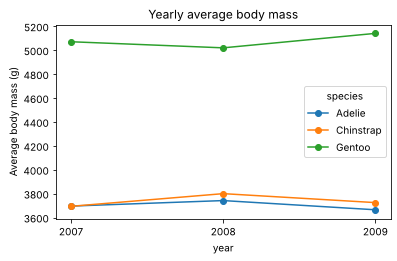

In [9]:
ax = df.pivot(index="year", columns="species", values="avg_mass_g").plot(marker="o")
ax.set_xticks([2007, 2008, 2009])
ax.set_ylabel("Average body mass (g)")
ax.set_title("Yearly average body mass")
plt.show()

## 07 · Attach scientific names from the dimension table.

```sql
-- 07 · Attach scientific names from the dimension table.
-- Technique: LEFT JOIN fact → dimension; a NULL scientific_name would reveal
-- a species missing from the dimension (referential-integrity check).
SELECT
    s.scientific_name,
    p.species,
    COUNT(p.id)                          AS n_penguins,
    COUNT(DISTINCT p.island)             AS n_islands,
    GROUP_CONCAT(DISTINCT p.island)      AS islands
FROM penguins p
LEFT JOIN species s ON s.species = p.species
GROUP BY p.species, s.scientific_name
ORDER BY n_penguins DESC;
```

In [10]:
df = run_query(conn, "07_join_species_dimension", as_frame=True)
df

,scientific_name,species,n_penguins,n_islands,islands
0,Pygoscelis adeliae,Adelie,152,3,"Biscoe,Dream,Torgersen"
1,Pygoscelis papua,Gentoo,124,1,Biscoe
2,Pygoscelis antarcticus,Chinstrap,68,1,Dream


## 08 · Median flipper length per species.

```sql
-- 08 · Median flipper length per species.
-- Technique: SQLite has no MEDIAN(); emulate it with ROW_NUMBER + COUNT windows and
-- average the one (odd n) or two (even n) middle values.
WITH ordered AS (
    SELECT
        species,
        flipper_length_mm,
        ROW_NUMBER() OVER (PARTITION BY species ORDER BY flipper_length_mm) AS rn,
        COUNT(*)     OVER (PARTITION BY species)                            AS cnt
    FROM penguins
    WHERE flipper_length_mm IS NOT NULL
)
SELECT species, AVG(flipper_length_mm) AS median_flipper_length_mm, MAX(cnt) AS n
FROM ordered
WHERE rn IN ((cnt + 1) / 2, (cnt + 2) / 2)
GROUP BY species
ORDER BY species;
```

In [11]:
df = run_query(conn, "08_median_flipper", as_frame=True)
df

,species,median_flipper_length_mm,n
0,Adelie,190.0,151
1,Chinstrap,196.0,68
2,Gentoo,216.0,123


## 09 · Body-mass histogram with 500 g buckets, pivoted by species.

```sql
-- 09 · Body-mass histogram with 500 g buckets, pivoted by species.
-- Technique: integer bucketing + CASE-based pivot (SQLite has no PIVOT keyword).
SELECT
    (body_mass_g / 500) * 500                          AS bucket_start_g,
    (body_mass_g / 500) * 500 + 499                    AS bucket_end_g,
    SUM(CASE WHEN species = 'Adelie'    THEN 1 ELSE 0 END) AS adelie,
    SUM(CASE WHEN species = 'Chinstrap' THEN 1 ELSE 0 END) AS chinstrap,
    SUM(CASE WHEN species = 'Gentoo'    THEN 1 ELSE 0 END) AS gentoo,
    COUNT(*)                                           AS total
FROM penguins
WHERE body_mass_g IS NOT NULL
GROUP BY bucket_start_g
ORDER BY bucket_start_g;
```

In [12]:
df = run_query(conn, "09_mass_histogram", as_frame=True)
df

,bucket_start_g,bucket_end_g,adelie,chinstrap,gentoo,total
0,2500,2999,7,2,0,9
1,3000,3499,47,15,0,62
2,3500,3999,58,35,1,94
3,4000,4499,31,13,15,59
4,4500,4999,8,3,40,51
5,5000,5499,0,0,34,34
6,5500,5999,0,0,29,29
7,6000,6499,0,0,4,4


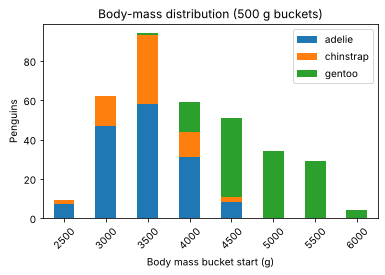

In [13]:
ax = df.set_index("bucket_start_g")[["adelie", "chinstrap", "gentoo"]].plot.bar(stacked=True, rot=45)
ax.set_xlabel("Body mass bucket start (g)")
ax.set_ylabel("Penguins")
ax.set_title("Body-mass distribution (500 g buckets)")
plt.show()

## 10 · Can a simple SQL rule tell species apart?

```sql
-- 10 · Can a simple SQL rule tell species apart?
-- Technique: CASE-expression "classifier" on bill shape, then a confusion matrix
-- via GROUP BY actual vs predicted. Thresholds chosen by eyeballing query 03.
WITH predicted AS (
    SELECT
        species AS actual,
        CASE
            WHEN bill_depth_mm < 16.5                       THEN 'Gentoo'
            WHEN bill_length_mm >= 43                        THEN 'Chinstrap'
            ELSE 'Adelie'
        END AS predicted
    FROM penguins
    WHERE bill_length_mm IS NOT NULL AND bill_depth_mm IS NOT NULL
)
SELECT
    actual,
    predicted,
    COUNT(*) AS n,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY actual), 1) AS pct_of_actual
FROM predicted
GROUP BY actual, predicted
ORDER BY actual, n DESC;
```

In [14]:
df = run_query(conn, "10_bill_ratio_classifier", as_frame=True)
df

,actual,predicted,n,pct_of_actual
0,Adelie,Adelie,137,90.7
1,Adelie,Chinstrap,8,5.3
2,Adelie,Gentoo,6,4.0
3,Chinstrap,Chinstrap,63,92.6
4,Chinstrap,Adelie,4,5.9
5,Chinstrap,Gentoo,1,1.5
6,Gentoo,Gentoo,115,93.5
7,Gentoo,Chinstrap,8,6.5


## Takeaways

* Gentoo live only on Biscoe and Chinstrap only on Dream; Adelie are on all three islands.
* Gentoo are the heaviest species by roughly 1 kg; males outweigh females in every species.
* Bill depth alone separates Gentoo; bill length then splits Adelie from Chinstrap — a two-rule `CASE` classifier gets over 90% right per species.
* Only two penguins are more than 2.5 standard deviations from their species mean.